# Тема 3. Крупные универсальные базы знаний


In [1]:
%pip install rdflib -q

## От содержательного вопроса к графовому шаблону

SPARQL предназначен для запросов к RDF-графам. В отличие от алгоритма поиска, запрос обычно не задаёт точный порядок обхода. Пользователь описывает шаблон требуемого фрагмента графа, а система подбирает значения переменных.

**Пример естественного вопроса:**

Какие люди родились в Москве и когда они родились?

**Графовый шаблон**

```text
?person --instance of--> human
?person --place of birth--> Moscow
?person --date of birth--> ?date
```
**SPARQL запрос**

```sparql
PREFIX wd: <http://www.wikidata.org/entity/>
PREFIX wdt: <http://www.wikidata.org/prop/direct/>
SELECT ?person ?date
WHERE {
  ?person wdt:P31 wd:Q5 ;
          wdt:P19 wd:Q1773 ;
          wdt:P569 ?date .
}
LIMIT 100
```

где `instance of` означает принадлежность экземпляра классу (`P31`), `place of birth` означает место рождения (`P19`), а `date of birth` означает дату рождения (`P569`); человек имеет идентификатор `Q5`, а Москва, как в семинаре 1, имеет идентификатор `Q649`.

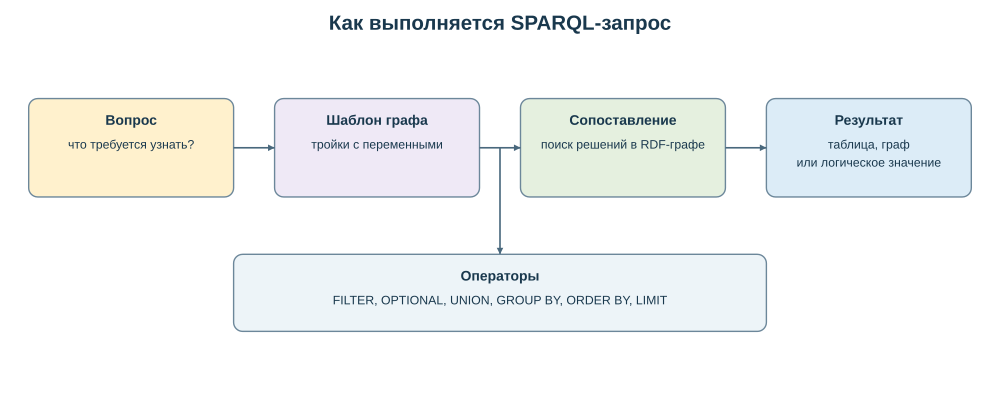

In [2]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="398" viewBox="0 0 1220 485" role="img" aria-label="Как выполняется SPARQL-запрос">
<rect width="1220" height="485" fill="#ffffff"/>
<defs><marker id="flowArrow" markerWidth="9" markerHeight="9" refX="8" refY="4" orient="auto" markerUnits="userSpaceOnUse"><path d="M0,0 L8,4 L0,8 Z" fill="#49687d"/></marker></defs>
<g font-family="Arial,DejaVu Sans,sans-serif" fill="#19384d">
<text x="610.0" y="36" text-anchor="middle" font-size="25" font-weight="700">Как выполняется SPARQL-запрос</text>
<rect x="35" y="120" width="250" height="120" rx="11" fill="#fff1cd" stroke="#6c879a" stroke-width="1.7"/><text x="160.0" y="152" text-anchor="middle" font-size="17" font-weight="700">Вопрос</text><text x="160.0" y="181" text-anchor="middle" font-size="15">что требуется узнать?</text><rect x="335" y="120" width="250" height="120" rx="11" fill="#efe9f6" stroke="#6c879a" stroke-width="1.7"/><text x="460.0" y="152" text-anchor="middle" font-size="17" font-weight="700">Шаблон графа</text><text x="460.0" y="181" text-anchor="middle" font-size="15">тройки с переменными</text><rect x="635" y="120" width="250" height="120" rx="11" fill="#e5f0df" stroke="#6c879a" stroke-width="1.7"/><text x="760.0" y="152" text-anchor="middle" font-size="17" font-weight="700">Сопоставление</text><text x="760.0" y="181" text-anchor="middle" font-size="15">поиск решений в RDF-графе</text><rect x="935" y="120" width="250" height="120" rx="11" fill="#dcecf7" stroke="#6c879a" stroke-width="1.7"/><text x="1060.0" y="152" text-anchor="middle" font-size="17" font-weight="700">Результат</text><text x="1060.0" y="181" text-anchor="middle" font-size="15">таблица, граф</text><text x="1060.0" y="203" text-anchor="middle" font-size="15">или логическое значение</text><path d="M285,180 L335,180" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#flowArrow)"/><path d="M585,180 L635,180" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#flowArrow)"/><path d="M885,180 L935,180" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#flowArrow)"/><path d="M610,180 L610,310" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#flowArrow)"/><rect x="285" y="310" width="650" height="94" rx="11" fill="#edf4f8" stroke="#6c879a" stroke-width="1.7"/><text x="610.0" y="342" text-anchor="middle" font-size="17" font-weight="700">Операторы</text><text x="610.0" y="371" text-anchor="middle" font-size="15">FILTER, OPTIONAL, UNION, GROUP BY, ORDER BY, LIMIT</text>
</g></svg>
"""

display(SVG(svg))

In [3]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import quote
from io import BytesIO
import csv, html, json, re

import rdflib
from rdflib import Graph, Namespace, URIRef, Literal
from rdflib.query import Result
from rdflib.compare import isomorphic
from rdflib.plugins.sparql.parser import parseQuery
from IPython.display import display, HTML, SVG

WORK_DIR = Path("seminar_2_core")
DATA_DIR, QUERY_DIR, RESULT_DIR = [WORK_DIR / x for x in ("data", "queries", "results")]
for folder in (DATA_DIR, QUERY_DIR, RESULT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

NS = {
    "wd": "http://www.wikidata.org/entity/",
    "wdt": "http://www.wikidata.org/prop/direct/",
    "p": "http://www.wikidata.org/prop/",
    "ps": "http://www.wikidata.org/prop/statement/",
    "pq": "http://www.wikidata.org/prop/qualifier/",
    "pr": "http://www.wikidata.org/prop/reference/",
    "wikibase": "http://wikiba.se/ontology#",
    "prov": "http://www.w3.org/ns/prov#",
    "rdf": "http://www.w3.org/1999/02/22-rdf-syntax-ns#",
    "rdfs": "http://www.w3.org/2000/01/rdf-schema#",
    "xsd": "http://www.w3.org/2001/XMLSchema#",
    "schema": "https://schema.org/",
    "ex": "https://example.org/sem3/",
}
PREFIXES = "\n".join(f"PREFIX {p}: <{iri}>" for p, iri in NS.items()) + "\n"
WD, EX = Namespace(NS["wd"]), Namespace(NS["ex"])


def show_table(headers, rows):
    head = "".join(f"<th>{html.escape(str(h))}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td>{html.escape(str(v))}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(
        '<div class="sem2-table" style="overflow-x:auto">'
        '<style>.sem2-table table{border-collapse:collapse;width:100%;font-size:14px;}'
        '.sem2-table th,.sem2-table td{border:1px solid #aaa;padding:8px;vertical-align:top;}'
        '.sem2-table th{background:#f0f4f7;color:#192f42;text-align:left;}'
        '.sem2-table td{background:#fff;color:#18222c;}</style>'
        f'<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table></div>'
    ))

print(f"RDFLib {rdflib.__version__}. Рабочая папка: {WORK_DIR}")

RDFLib 7.6.0. Рабочая папка: seminar_2_core


### Исходный граф

| Учебная сущность | Прямой класс | Место рождения | Дата рождения | Профессии |
|---|---|---|---|---|
| `ex:PersonA` | человек | Москва | 15.02.1980 | математик, исследователь |
| `ex:PersonB` | человек | Москва | 10.07.1899 | математик |
| `ex:PersonC` | человек | Москва | не записана | исследователь |
| `ex:PersonD` | историческая личность, учебный подкласс человека | Москва | 20.03.1925 | математик |
| `ex:PersonOther` | человек | другой учебный город | 01.01.1970 | исследователь |

У исследователя А профессии дополнительно представлены полными утверждениями: у математика указаны начало деятельности и два учебных источника, а у исследователя указано начало деятельности без источника. Поэтому на одном наборе можно увидеть как пропуски, так и повторение строк.

In [4]:
TTL = "\n".join(f"@prefix {p}: <{iri}> ." for p, iri in NS.items()) + r"""

# СИНТЕТИЧЕСКИЙ УЧЕБНЫЙ ГРАФ, НЕ ВЫГРУЗКА WIKIDATA.
# Все ex:Person..., даты, профессии и источники составлены для занятия.
wd:Q649 rdfs:label "Москва"@ru .
wd:Q5 rdfs:label "человек"@ru .
ex:HistoricalPerson rdfs:label "историческая личность: учебный класс"@ru ;
    wdt:P279 wd:Q5 .
ex:Math rdfs:label "математик: учебный код"@ru .
ex:Science rdfs:label "исследователь: учебный код"@ru .
ex:OtherCity rdfs:label "другой учебный город"@ru .

ex:PersonA rdfs:label "Учебный исследователь А"@ru ;
    wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 ;
    wdt:P569 "1980-02-15T00:00:00Z"^^xsd:dateTime ;
    wdt:P106 ex:Math, ex:Science ; p:P106 ex:jobA_math, ex:jobA_science .
ex:PersonB rdfs:label "Учебный исследователь Б"@ru ;
    wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 ;
    wdt:P569 "1899-07-10T00:00:00Z"^^xsd:dateTime ; wdt:P106 ex:Math .
ex:PersonC rdfs:label "Учебный исследователь В"@ru ;
    wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 ; wdt:P106 ex:Science .
ex:PersonD rdfs:label "Учебный исследователь Г"@ru ;
    wdt:P31 ex:HistoricalPerson ; wdt:P19 wd:Q649 ;
    wdt:P569 "1925-03-20T00:00:00Z"^^xsd:dateTime ; wdt:P106 ex:Math .
ex:PersonOther rdfs:label "Исследователь другого города"@ru ;
    wdt:P31 wd:Q5 ; wdt:P19 ex:OtherCity ;
    wdt:P569 "1970-01-01T00:00:00Z"^^xsd:dateTime ; wdt:P106 ex:Science .

# Оба утверждения normal: в учебной модели оба входят в прямое представление.
ex:jobA_math a wikibase:BestRank ; ps:P106 ex:Math ;
    pq:P580 "2005-01-01T00:00:00Z"^^xsd:dateTime ;
    wikibase:rank wikibase:NormalRank ;
    prov:wasDerivedFrom ex:refA1, ex:refA2 .
ex:jobA_science a wikibase:BestRank ; ps:P106 ex:Science ;
    pq:P580 "2010-01-01T00:00:00Z"^^xsd:dateTime ;
    wikibase:rank wikibase:NormalRank .
ex:refA1 pr:P248 ex:Catalogue .
ex:refA2 pr:P248 ex:Archive .
ex:Catalogue rdfs:label "Учебный каталог: не реальный источник"@ru .
ex:Archive rdfs:label "Учебный архив: не реальный источник"@ru .
"""

DATA_PATH = DATA_DIR / "moscow_training.ttl"
if not DATA_PATH.exists():
    DATA_PATH.write_text(TTL, encoding="utf-8")
    print("Создан файл:", DATA_PATH)
else:
    print("Прочитан существующий файл:", DATA_PATH)

g = Graph().parse(DATA_PATH, format="turtle")
for prefix, iri in NS.items():
    g.bind(prefix, Namespace(iri))
ORIGINAL_DATA = isomorphic(g, Graph().parse(data=TTL, format="turtle"))
print("Режим: синтетический учебный граф. Троек:", len(g))
print("Файл соответствует встроенному образцу:", ORIGINAL_DATA)

Прочитан существующий файл: seminar_2_core/data/moscow_training.ttl
Режим: синтетический учебный граф. Троек: 48
Файл соответствует встроенному образцу: True


In [5]:
RESULTS, QUERIES = {}, {}


def term_text(value, graph):
    if value is None:
        return "не связано"
    if isinstance(value, URIRef):
        return value.n3(graph.namespace_manager)
    if isinstance(value, Literal):
        return str(value)  # типы литералов сохранены в файле JSON
    return str(value)


def run_local(name, body, graph=None, folder=None):
    """Сохранить .rq, выполнить SPARQL через RDFLib и показать реальный ответ."""
    graph = g if graph is None else graph
    folder = WORK_DIR if folder is None else Path(folder)
    if not re.fullmatch(r"[A-Za-z0-9_-]+", name):
        raise ValueError("Имя результата должно содержать только буквы ASCII, цифры, '_' или '-'.")
    if re.search(r"\b(SERVICE|FROM)\b", body, re.IGNORECASE):
        raise ValueError("Локальный пример не обращается в сеть; используйте отдельные ссылки WDQS.")
    query = PREFIXES + body.strip()
    parseQuery(query)
    query_dir, result_dir = folder / "queries", folder / "results"
    query_dir.mkdir(parents=True, exist_ok=True)
    result_dir.mkdir(parents=True, exist_ok=True)
    query_path = query_dir / f"{name}.rq"
    query_path.write_text(query, encoding="utf-8")
    answer = graph.query(query_path.read_text(encoding="utf-8"))
    print(f"{name} | RDFLib | локальный учебный граф")
    if answer.type == "SELECT":
        rows = list(answer)
        show_table([str(v) for v in answer.vars],
                   [[term_text(v, graph) for v in row] for row in rows])
        for fmt in ("json", "csv"):
            (result_dir / f"{name}.{fmt}").write_bytes(answer.serialize(format=fmt))
        print("Строк:", len(rows))
    elif answer.type == "ASK":
        print("Логический ответ:", "true" if bool(answer) else "false")
        (result_dir / f"{name}.json").write_bytes(answer.serialize(format="json"))
    elif answer.type == "CONSTRUCT":
        answer.graph.serialize(destination=str(result_dir / f"{name}.ttl"), format="turtle")
        print(answer.graph.serialize(format="turtle"))
        print("Троек:", len(answer.graph))
    else:
        raise ValueError(f"Форма {answer.type} не используется в этом практикуме.")
    (result_dir / f"{name}.meta.json").write_text(json.dumps({
        "data_kind": "synthetic_training_graph", "engine": f"RDFLib {rdflib.__version__}",
        "executed_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "query_file": str(query_path), "result_type": answer.type,
    }, ensure_ascii=False, indent=2), encoding="utf-8")
    RESULTS[name], QUERIES[name] = answer, body.strip()
    return answer

**Пример естественного вопроса:**

Какие люди родились в Москве и когда они родились?

**Результат запроса.** Ниже выполняется запрос, где одна строка означает пару *человек и найденная дата рождения*.

In [6]:
Q_FIRST = """
SELECT ?person ?date
WHERE {
  ?person wdt:P31 wd:Q5 ;
          wdt:P19 wd:Q649 ;
          wdt:P569 ?date .
}
LIMIT 100
"""
r_first = run_local("people_with_date", Q_FIRST)

people_with_date | RDFLib | локальный учебный граф


person,date
ex:PersonA,1980-02-15T00:00:00+00:00
ex:PersonB,1899-07-10T00:00:00+00:00


Строк: 2


#### Как прочитать полученный ответ

В исходном образце найдены **А и B**, поскольку у них одновременно есть нужный прямой класс, место рождения и дата. **C** не найден из-за отсутствующей даты, **D** имеет другой прямой класс, а пятый человек относится к другому городу. 


**Решение запроса** представляет подстановку найденных RDF-значений вместо переменных, поэтому строку исследователя А можно записать так:

$$
\mu(?person)=\mathrm{ex{:}PersonA},\qquad
\mu(?date)=\text{1980-02-15T00:00:00Z}^{\wedge\wedge}\mathrm{xsd{:}dateTime}.
$$

Совпадение имени `?person` в трёх шаблонах требует одной и той же сущности: если заменить его в одном из условий на другую переменную, связь условий изменится. Порядок двух строк первого ответа не фиксирован, поскольку в запросе нет `ORDER BY`.

## Формы запросов и место их выполнения

| Форма | Что возвращается | Что сохраняется | Как читать результат |
|---|---|---|---|
| `SELECT` | Строки подстановок переменных | `.json` и `.csv` | Каждая строка должна иметь заранее заданный смысл |
| `ASK` | Логическое значение | `.json` | Найдено ли хотя бы одно решение в данном графе |
| `CONSTRUCT` | RDF-граф по явному шаблону | `.ttl` | Какие тройки построены из найденных решений |
| `DESCRIBE` | Описание ресурсов | RDF-файл | Состав зависит от реализации сервиса |

**SPARQL-эндпоинт** — сетевой сервис, принимающий запрос и возвращающий результат в стандартизованном формате. Для Wikidata используется веб-интерфейс Wikidata Query Service и программный адрес:
```text
https://query.wikidata.org/sparql
```
Для DBpedia:
```text
https://dbpedia.org/sparql
```
Публичный эндпоинт является общим ресурсом и не предназначен для запросов без ограничений, массового параллельного сканирования или повторения ошибочного запроса сотни раз в секунду.

### Решение запроса

**Решение запроса** представляет собой частичное отображение переменных в RDF-термы, которое называется частичным, поскольку значение может быть найдено не для каждой переменной:

$$
\mu:\mathrm{Var}\rightharpoonup T,\qquad T=I\cup B\cup L.
$$

где $\mathrm{Var}$ обозначает множество переменных запроса,  $T$ - множество RDF-термов, а $I$, $B$ и $L$ - множество IRI, пустых узлов и литералов. 

Если `?person` получил значение `ex:PersonA`, а `?date` не получил значения, решение всё равно может существовать, когда дата запрашивается необязательно. 
Множество переменных, для которых значение определено, обозначим $\operatorname{dom}(\mu)$; два решения совместимы, когда совпадают значения всех общих связанных переменных:

$$
\mu_1\sim\mu_2\iff
\forall v\in\operatorname{dom}(\mu_1)\cap\operatorname{dom}(\mu_2):
\mu_1(v)=\mu_2(v).
$$

Именно по совместимым решениям выполняется **соединение**, связывающее результаты отдельных шаблонов:

$$
\Omega=\Omega_1\bowtie\Omega_2.
$$


## Необязательное поле: OPTIONAL

**Необязательный графовый шаблон (optional graph pattern)** дополняет уже найденное решение, если совпадение существует, но не исключает исходное решение при отсутствии совпадения. В SPARQL он записывается конструкцией `OPTIONAL { ... }`.

**Вопрос.** Как получить всех людей с прямым классом `Q5` и местом рождения Москвой, даже когда дата рождения не записана?

**Графовый шаблон.** 

```text
исходный набор ?person
?person → P569 → ?date (необязательно)
```
Класс и город остаются обязательными, а условие `?person wdt:P569 ?date` становится дополнительным.


In [7]:
Q_BASE = """
SELECT ?person WHERE {
  ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 .
}
ORDER BY ?person
"""
Q_OPTIONAL = """
SELECT ?person ?date WHERE {
  ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 .
  OPTIONAL { ?person wdt:P569 ?date . }
}
ORDER BY ?person
"""
r_base = run_local("people_base", Q_BASE)
r_optional = run_local("people_optional", Q_OPTIONAL)
show_table(["Запрос", "Строк"], [
    ["Только класс и город", len(r_base)],
    ["С обязательной датой", len(r_first)],
    ["С необязательной датой", len(r_optional)],
])

people_base | RDFLib | локальный учебный граф


person
ex:PersonA
ex:PersonB
ex:PersonC


Строк: 3
people_optional | RDFLib | локальный учебный граф


person,date
ex:PersonA,1980-02-15T00:00:00+00:00
ex:PersonB,1899-07-10T00:00:00+00:00
ex:PersonC,не связано


Строк: 3


Запрос,Строк
Только класс и город,3
С обязательной датой,2
С необязательной датой,3


##### Почему человек без даты сохранился

Исходный запрос находит **трёх** людей, запрос с обязательной датой - **двух**, а `OPTIONAL` снова возвращает **трёх**, оставляя дату исследователя **В** несвязанной. Это означает отсутствие значения в данном графе, а не отсутствие даты рождения в реальности.

Конструкция `A OPTIONAL { B }` сохраняет решения обязательной, левой части и дополняет их совместимыми решениями необязательной, правой части. Если дополнительное свойство имеет несколько значений, одному человеку могут соответствовать несколько строк, поэтому `OPTIONAL` сохраняет исходные сущности, но не гарантирует неизменное число строк.

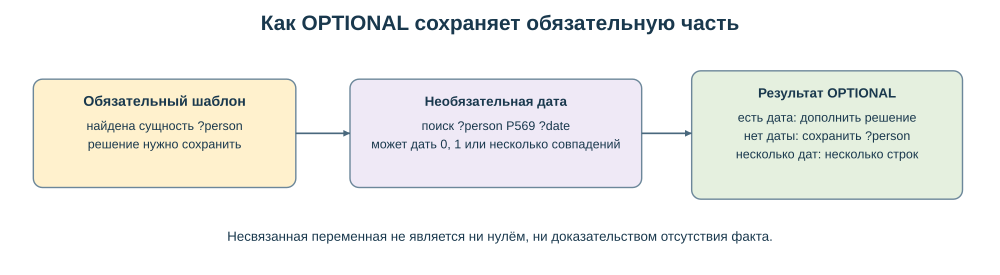

In [8]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="275" viewBox="0 0 1200 330" role="img" aria-label="Как OPTIONAL сохраняет обязательную часть">
<rect width="1200" height="330" fill="#ffffff"/>
<defs><marker id="optArrow" markerWidth="9" markerHeight="9" refX="8" refY="4" orient="auto" markerUnits="userSpaceOnUse"><path d="M0,0 L8,4 L0,8 Z" fill="#49687d"/></marker></defs>
<g font-family="Arial,DejaVu Sans,sans-serif" fill="#19384d">
<text x="600.0" y="36" text-anchor="middle" font-size="25" font-weight="700">Как OPTIONAL сохраняет обязательную часть</text>
<rect x="40" y="95" width="315" height="130" rx="11" fill="#fff1cd" stroke="#6c879a" stroke-width="1.7"/><text x="197.5" y="127" text-anchor="middle" font-size="17" font-weight="700">Обязательный шаблон</text><text x="197.5" y="156" text-anchor="middle" font-size="15">найдена сущность ?person</text><text x="197.5" y="178" text-anchor="middle" font-size="15">решение нужно сохранить</text><rect x="420" y="95" width="350" height="130" rx="11" fill="#efe9f6" stroke="#6c879a" stroke-width="1.7"/><text x="595.0" y="127" text-anchor="middle" font-size="16" font-weight="700">Необязательная дата</text><text x="595.0" y="156" text-anchor="middle" font-size="15">поиск ?person P569 ?date</text><text x="595.0" y="178" text-anchor="middle" font-size="15">может дать 0, 1 или несколько совпадений</text><rect x="830" y="85" width="325" height="154" rx="11" fill="#e5f0df" stroke="#6c879a" stroke-width="1.7"/><text x="992.5" y="117" text-anchor="middle" font-size="16" font-weight="700">Результат OPTIONAL</text><text x="992.5" y="146" text-anchor="middle" font-size="15">есть дата: дополнить решение</text><text x="992.5" y="168" text-anchor="middle" font-size="15">нет даты: сохранить ?person</text><text x="992.5" y="190" text-anchor="middle" font-size="15">несколько дат: несколько строк</text><path d="M355,160 L420,160" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#optArrow)"/><path d="M770,160 L830,160" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#optArrow)"/><text x="600" y="289" text-anchor="middle" font-size="16">Несвязанная переменная не является ни нулём, ни доказательством отсутствия факта.</text>
</g></svg>
"""

display(SVG(svg))

## Отбор по условию: FILTER

`FILTER` сохраняет решения, для которых выражение принимает истинное значение, поэтому сначала нужно понять, какие значения были найдены шаблоном, а затем определить условие их отбора. В обозначениях это может быть выражено как:

$$
\operatorname{Filter}_{F}(\Omega)=\{\mu\in\Omega\mid F(\mu)=\mathrm{true}\}.
$$

**Вопрос.** Какие люди из прямой выборки родились не раньше 1 января 1900 года?

**Графовый шаблон.** Используются класс, Москва и обязательная дата, к которой добавляется сравнение с границей периода.

Для даты применяется сравнение с типизированным значением, например `FILTER(?date >= "1900-01-01T00:00:00Z"^^xsd:dateTime)`, которое означает **с начала 1900 года**, а не строго после его окончания.

In [9]:
Q_FILTER = """
SELECT ?person ?date WHERE {
  ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 ; wdt:P569 ?date .
  FILTER(?date >= "1900-01-01T00:00:00Z"^^xsd:dateTime)
}
ORDER BY ?date ?person
"""
r_filter = run_local("people_filtered", Q_FILTER)

people_filtered | RDFLib | локальный учебный граф


person,date
ex:PersonA,1980-02-15T00:00:00+00:00


Строк: 1


**Результат:** в образце остался только А с датой 1980 года, поскольку 1899 год не проходит границу, а человек без даты не удовлетворяет обязательному шаблону.

Фильтр по строке
`FILTER(CONTAINS(LCASE(?label), "university"))`

Фильтр по языку
`FILTER(LANG(?label) = "ru")`

Место фильтра важно: если записать `OPTIONAL { ?person wdt:P569 ?date . FILTER(...) }`, все исходные люди сохранятся, но дата будет показана только при выполнении условия. Если записать такой фильтр после `OPTIONAL`, строки без подходящей даты будут исключены.

### DISTINCT

Графовые пути и многозначные свойства могут создавать дубликаты строк. SELECT DISTINCT удаляет повторяющиеся проекции.

**Вопрос.** Как получить каждого человека с записанной профессией только один раз?

**Графовый шаблон.** Условия поиска остаются прежними, но в `SELECT` оставляется только `?person`.


```text
?person → P... → ?occupation
проекция ?person
удаление одинаковых проекций
```

**Проекция (projection)** означает выбор выводимых переменных, поэтому после скрытия профессии два разных решения для А выглядят одинаково. `DISTINCT` удаляет одинаковые строки именно среди выбранных столбцов.


In [10]:
Q_PROJECTED = """
SELECT ?person WHERE {
  ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 ; wdt:P106 ?occupation .
}
ORDER BY ?person
"""
Q_DISTINCT = Q_PROJECTED.replace("SELECT ?person", "SELECT DISTINCT ?person")
r_projected = run_local("people_projection", Q_PROJECTED)
r_distinct = run_local("people_distinct", Q_DISTINCT)

people_projection | RDFLib | локальный учебный граф


person
ex:PersonA
ex:PersonA
ex:PersonB
ex:PersonC


Строк: 4
people_distinct | RDFLib | локальный учебный граф


person
ex:PersonA
ex:PersonB
ex:PersonC


Строк: 3


**Результат:** у трёх людей найдены четыре пары *человек и профессия*, поэтому после скрытия профессии без `DISTINCT` по-прежнему остаются четыре строки, а с `DISTINCT` остаются три. Если оставить в `SELECT` и человека, и профессию, `DISTINCT` не объединит разные профессии, поскольку такие строки различаются.

## Альтернативные условия: VALUES и UNION

`VALUES` задаёт небольшой перечень допустимых значений переменной, тогда как `UNION` объединяет решения альтернативных шаблонов.

**Вопрос.** У кого из исходного набора записана профессия математика или физика?

**Графовый шаблон.**

```text
исходный набор ?person
?person → P106 → ?occupation
?occupation входит в {Q..., Q...}
```


In [25]:
query = r"""
SELECT DISTINCT ?person WHERE {
  {
    SELECT DISTINCT ?person WHERE {
      ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 .
    }
    ORDER BY ?person
    LIMIT 25
  }
  VALUES ?occupation { wd:Q170790 wd:Q169470 }
  ?person wdt:P106 ?occupation .
}
ORDER BY ?person
"""

Для каждого человека ищется хотя бы одно значение P106 из заданного перечня. Наличие обеих профессий допустимо, но итоговая проекция содержит человека один раз.

**Вопрос.** Как выразить тот же отбор математиков или физиков двумя альтернативными шаблонами?

**Графовый шаблон.**

```text
исходный набор ?person
{?person → P106 → Q...} ИЛИ {?person → P106 → Q...}
```

In [26]:
query = r"""
SELECT DISTINCT ?person WHERE {
  {
    SELECT DISTINCT ?person WHERE {
      ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 .
    }
    ORDER BY ?person
    LIMIT 25
  }
  { ?person wdt:P106 wd:Q170790 . }
  UNION
  { ?person wdt:P106 wd:Q169470 . }
}
ORDER BY ?person
"""

Решения обеих ветвей объединяются, после чего DISTINCT оставляет различные значения ?person; на неизменных данных результат должен совпасть с вариантом VALUES.

## Сортировка и ограничение выдачи

| Задача | Конструкция | Что делает |
|---|---|---|
| Удалить одинаковые выводимые строки | `DISTINCT` | Изменяет число повторений |
| Задать порядок | `ORDER BY` | Упорядочивает строки, не удаляя их |
| Показать не больше заданного числа строк | `LIMIT` | Ограничивает размер ответа |

**Вопрос.** Кто первые двое в прямой выборке, если сначала показывать более поздние известные даты рождения?

**Графовый шаблон.** Берём уже разобранный запрос с `OPTIONAL`, не меняя его условий.

 `ORDER BY DESC(?date) ?person` сортирует даты по убыванию, а идентификатор человека задаёт дополнительный порядок при равных датах; затем `LIMIT 2` оставляет две строки.

In [11]:
Q_ORDER_LIMIT = Q_OPTIONAL.replace("ORDER BY ?person", "ORDER BY DESC(?date) ?person\nLIMIT 2")
r_order_limit = run_local("people_order_limit", Q_ORDER_LIMIT)

people_order_limit | RDFLib | локальный учебный граф


person,date
ex:PersonA,1980-02-15T00:00:00+00:00
ex:PersonB,1899-07-10T00:00:00+00:00


Строк: 2


**Результат:** сначала показан А с 1980 годом, затем Б с 1899 годом, тогда как В не попал в первые две строки; он не исчез из исходной выборки, а оказался за пределом выдачи. Без `ORDER BY` ограничение `LIMIT 2` не задавало бы, какие именно две строки требуется вернуть.

## Группировка 

**Агрегатная функция (aggregate function)** вычисляет одно значение по группе решений, а **группировка (grouping)** объединяет решения по значениям выражений в `GROUP BY`; в отличие от `BIND`, такая операция изменяет смысл строки ответа с отдельного факта на группу.

| Выражение | Что считается |
|---|---|
| `COUNT(*)` | Все решения группы |
| `COUNT(?person)` | Решения, в которых `?person` связано |
| `COUNT(DISTINCT ?person)` | Различные связанные значения человека |
| `SUM`, `AVG`, `MIN`, `MAX` | Сумма, среднее, минимум и максимум соответствующих значений |
| `GROUP_CONCAT` | Строковое объединение значений группы |

Для числа различных людей некоторой профессии $o$ можно записать

$$n_o=\left|\{p:(p,o)\text{ найдено в рассматриваемом наборе}\}\right|.$$


In [12]:
Q_COUNT = """
SELECT ?occupation (COUNT(DISTINCT ?person) AS ?peopleCount) WHERE {
  ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 ; wdt:P106 ?occupation .
}
GROUP BY ?occupation
ORDER BY DESC(?peopleCount) ?occupation
"""
r_count = run_local("people_count", Q_COUNT)

people_count | RDFLib | локальный учебный граф


occupation,peopleCount
ex:Math,2
ex:Science,2


Строк: 2


**Результат:** в образце два математика и два исследователя, хотя всего людей трое, поскольку А входит в обе группы. Сумма количеств по профессиям поэтому не обязана совпадать с числом людей, а значения учебного графа не являются статистикой населения Москвы.

## Учет подкласса

**Вопрос.** Как включить `PersonD`, у которого записан не прямой класс человека, а его учебный подкласс?

**Графовый шаблон.** Вместо одного перехода `wdt:P31 wd:Q5` используем `wdt:P31/wdt:P279* wd:Q5`.

**Путь свойств (property path)** задаёт последовательность переходов по графу: `/` соединяет шаги, а `*` допускает ноль или больше переходов `P279`. 

**Путь свойств (property path)** записывает последовательность или альтернативу переходов между RDF-узлами, благодаря чему запрос может учитывать не только прямой класс, но и цепочку подклассов.

| Оператор пути | Смысл |
|---|---|
| `/` | Последовательные переходы |
| `\|` | Альтернативный переход |
| `*` | Ноль или более переходов |
| `+` | Один или более переходов |
| `?` | Ноль или один переход |
| `^` | Обратное направление |

Путь `wdt:P31/wdt:P279*` сначала находит прямой класс, затем допускает ноль или несколько шагов к более общему классу; нулевой шаг означает, что прямой класс уже равен целевому. Это явно заданное условие поиска, а не обещание автоматического OWL-вывода или безошибочной иерархии.

In [13]:
Q_PATH = """
SELECT DISTINCT ?person WHERE {
  ?person wdt:P31/wdt:P279* wd:Q5 ; wdt:P19 wd:Q649 .
}
ORDER BY ?person
"""
r_path = run_local("people_class_path", Q_PATH)
print("По прямому классу:", len(r_base), "| С учетом подкласса:", len(r_path))

people_class_path | RDFLib | локальный учебный граф


person
ex:PersonA
ex:PersonB
ex:PersonC
ex:PersonD


Строк: 4
По прямому классу: 3 | С учетом подкласса: 4


**Результат:** к А, B и C добавился D, поэтому найдено четыре человека. Исследователь другого города по-прежнему не проходит условие Москвы. Для проверки изменения можно открыть `.ttl` и найти единственную цепочку `ex:PersonD → ex:HistoricalPerson → wd:Q5`.

## От значения к контексту утверждения

Как было показано ранее профессию мы получали через `wdt:P106`, но такая тройка не показывает, когда началась деятельность и на какой источник ссылается запись. Чтобы получить эти сведения необходимо вернуться к полной модели из предыдущего семинара.

| Связь | Для чего используется в примере |
|---|---|
| `p:P106` | Перейти от человека к узлу утверждения о профессии |
| `ps:P106` | Получить профессию этого утверждения |
| `pq:P580` | Получить квалификатор начала деятельности |
| `wikibase:rank` | Прочитать ранг утверждения |
| `prov:wasDerivedFrom` | Перейти к записи ссылки на источник |
| `pr:P248` | Получить источник, указанный в этой записи |

Здесь **начало периода (start time, P580)** обозначает дату, с которой относится выбранное утверждение, поэтому его не следует путать с датой рождения. В модели оба утверждения А имеют обычный ранг и включены в прямое представление; RDFLib не рассчитывает это автоматически, а читает сохранённые тройки.

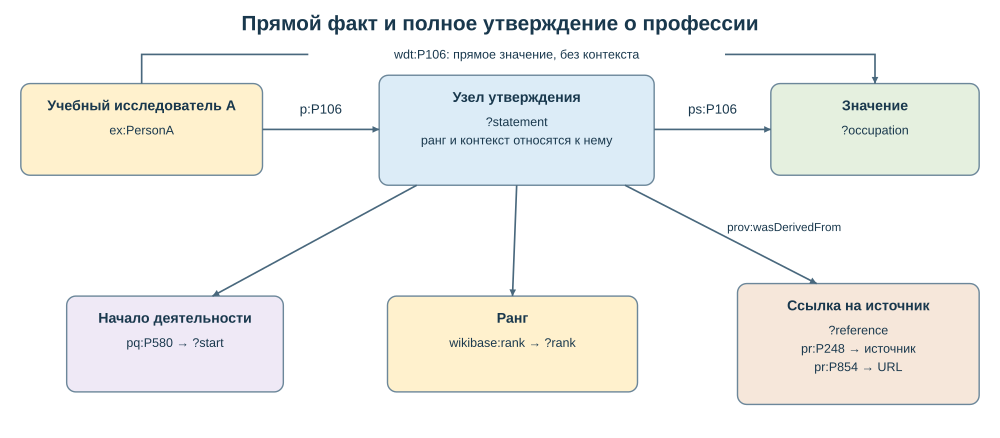

In [14]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="438" viewBox="0 0 1200 525" role="img" aria-label="Прямой факт и полное утверждение о профессии">
<rect width="1200" height="525" fill="#ffffff"/>
<defs><marker id="stmtArrow" markerWidth="9" markerHeight="9" refX="8" refY="4" orient="auto" markerUnits="userSpaceOnUse"><path d="M0,0 L8,4 L0,8 Z" fill="#49687d"/></marker></defs>
<g font-family="Arial,DejaVu Sans,sans-serif" fill="#19384d">
<text x="600.0" y="36" text-anchor="middle" font-size="25" font-weight="700">Прямой факт и полное утверждение о профессии</text>
<rect x="25" y="100" width="290" height="110" rx="11" fill="#fff1cd" stroke="#6c879a" stroke-width="1.7"/><text x="170.0" y="132" text-anchor="middle" font-size="17" font-weight="700">Учебный исследователь А</text><text x="170.0" y="161" text-anchor="middle" font-size="15">ex:PersonA</text><rect x="455" y="90" width="330" height="132" rx="11" fill="#dcecf7" stroke="#6c879a" stroke-width="1.7"/><text x="620.0" y="122" text-anchor="middle" font-size="17" font-weight="700">Узел утверждения</text><text x="620.0" y="151" text-anchor="middle" font-size="15">?statement</text><text x="620.0" y="173" text-anchor="middle" font-size="15">ранг и контекст относятся к нему</text><rect x="925" y="100" width="250" height="110" rx="11" fill="#e5f0df" stroke="#6c879a" stroke-width="1.7"/><text x="1050.0" y="132" text-anchor="middle" font-size="17" font-weight="700">Значение</text><text x="1050.0" y="161" text-anchor="middle" font-size="15">?occupation</text><path d="M315,155 L455,155" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#stmtArrow)"/><path d="M785,155 L925,155" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#stmtArrow)"/><text x="385" y="136" text-anchor="middle" font-size="16">p:P106</text><text x="855" y="136" text-anchor="middle" font-size="16">ps:P106</text><rect x="80" y="355" width="260" height="115" rx="11" fill="#efe9f6" stroke="#6c879a" stroke-width="1.7"/><text x="210.0" y="387" text-anchor="middle" font-size="17" font-weight="700">Начало деятельности</text><text x="210.0" y="416" text-anchor="middle" font-size="15">pq:P580 → ?start</text><rect x="465" y="355" width="300" height="115" rx="11" fill="#fff1cd" stroke="#6c879a" stroke-width="1.7"/><text x="615.0" y="387" text-anchor="middle" font-size="17" font-weight="700">Ранг</text><text x="615.0" y="416" text-anchor="middle" font-size="15">wikibase:rank → ?rank</text><rect x="885" y="340" width="290" height="145" rx="11" fill="#f6e7da" stroke="#6c879a" stroke-width="1.7"/><text x="1030.0" y="372" text-anchor="middle" font-size="17" font-weight="700">Ссылка на источник</text><text x="1030.0" y="401" text-anchor="middle" font-size="15">?reference</text><text x="1030.0" y="423" text-anchor="middle" font-size="15">pr:P248 → источник</text><text x="1030.0" y="445" text-anchor="middle" font-size="15">pr:P854 → URL</text><path d="M500,222 L255,355" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#stmtArrow)"/><path d="M620,222 L615,355" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#stmtArrow)"/><path d="M750,222 L980,340" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#stmtArrow)"/><text x="941" y="277" text-anchor="middle" font-size="14">prov:wasDerivedFrom</text><path d="M170,100 L170,65 L1050,65 L1050,100" stroke="#49687d" stroke-width="2" fill="none" marker-end="url(#stmtArrow)"/><rect x="370" y="53" width="500" height="23" fill="white"/><text x="620" y="70" text-anchor="middle" font-size="15">wdt:P106: прямое значение, без контекста</text>
</g></svg>
"""

display(SVG(svg))

### Когда началась деятельность и чем она подтверждена

**Вопрос.** Какие профессии записаны у А, с какого момента они указаны и какие источники приведены?

**Графовый шаблон.** `ex:PersonA → p:P106 → ?statement → ps:P106 → ?occupation`, от узла утверждения отдельно читаются начало периода, ранг и источники.

Квалификатор и источники присоединяются через `OPTIONAL`, поэтому утверждение без источника не пропадает; если у одного утверждения две ссылки, появятся две строки с тем же `?statement`.


In [15]:
Q_CONTEXT = """
SELECT ?statement ?occupation ?start ?rank ?reference ?source WHERE {
  ex:PersonA p:P106 ?statement .
  ?statement ps:P106 ?occupation ; wikibase:rank ?rank .
  OPTIONAL { ?statement pq:P580 ?start . }
  OPTIONAL {
    ?statement prov:wasDerivedFrom ?reference .
    OPTIONAL { ?reference pr:P248 ?source . }
  }
}
ORDER BY ?statement ?reference
"""
r_context = run_local("person_context", Q_CONTEXT)
statement_ids = {row.statement for row in r_context}
print("Различных утверждений:", len(statement_ids), "| Строк после добавления источников:", len(r_context))

person_context | RDFLib | локальный учебный граф


statement,occupation,start,rank,reference,source
ex:jobA_math,ex:Math,2005-01-01T00:00:00+00:00,wikibase:NormalRank,ex:refA1,ex:Catalogue
ex:jobA_math,ex:Math,2005-01-01T00:00:00+00:00,wikibase:NormalRank,ex:refA2,ex:Archive
ex:jobA_science,ex:Science,2010-01-01T00:00:00+00:00,wikibase:NormalRank,не связано,не связано


Строк: 3
Различных утверждений: 2 | Строк после добавления источников: 3


**Результат:** два утверждения дали три строки, поскольку у математической деятельности есть две ссылки, а у исследовательской деятельности ссылка не записана. Первые две строки относятся к одному `ex:jobA_math`, поэтому считать их двумя разными профессиями было бы ошибкой.


## Проверка наличия факта: ASK

**Вопрос.** Записана ли дата рождения у В?

**Графовый шаблон.** Ищем хотя бы одну тройку `ex:PersonC wdt:P569 ?date`.

**Сопоставление.** `ASK` возвращает логическое значение, а не таблицу, поэтому достаточно существования одного совпадения.


In [16]:
r_ask = run_local("person_has_date", "ASK { ex:PersonC wdt:P569 ?date . }")

person_has_date | RDFLib | локальный учебный граф
Логический ответ: false


**Результат `false`** означает, что нужная тройка не найдена в данном графе; он не означает, что человек не имеет даты рождения. В настоящей Wikidata отсутствие найденного значения тоже нельзя без дополнительного обоснования превращать в отрицательный факт.

## Сохранение результата как нового графа: CONSTRUCT

**Вопрос.** Как сохранить найденных людей, их метки, место рождения и известные даты в отдельном RDF-файле?

**Графовый шаблон.** `WHERE` находит тот же набор прямых экземпляров, а `CONSTRUCT` задаёт тройки в схеме Schema.org, которая использовалась в предыдущих темах.

Для каждого решения создаются тройки по шаблону; тройка с несвязанной датой не создаётся, но остальные сведения о человеке сохраняются.


In [17]:
Q_CONSTRUCT = """
CONSTRUCT {
  ?person a schema:Person ; schema:name ?name ;
          schema:birthPlace wd:Q649 ; schema:birthDate ?date .
}
WHERE {
  ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 .
  OPTIONAL { ?person rdfs:label ?name . }
  OPTIONAL { ?person wdt:P569 ?date . }
}
"""
r_construct = run_local("people_graph", Q_CONSTRUCT)
reloaded_graph = Graph().parse(RESULT_DIR / "people_graph.ttl", format="turtle")
assert isomorphic(r_construct.graph, reloaded_graph)
print("Повторное чтение Turtle: граф сохранён без потери троек.")

people_graph | RDFLib | локальный учебный граф
@prefix schema: <https://schema.org/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

<https://example.org/sem3/PersonA> a schema:Person ;
    schema:birthDate "1980-02-15T00:00:00+00:00"^^xsd:dateTime ;
    schema:birthPlace <http://www.wikidata.org/entity/Q649> ;
    schema:name "Учебный исследователь А"@ru .

<https://example.org/sem3/PersonB> a schema:Person ;
    schema:birthDate "1899-07-10T00:00:00+00:00"^^xsd:dateTime ;
    schema:birthPlace <http://www.wikidata.org/entity/Q649> ;
    schema:name "Учебный исследователь Б"@ru .

<https://example.org/sem3/PersonC> a schema:Person ;
    schema:birthPlace <http://www.wikidata.org/entity/Q649> ;
    schema:name "Учебный исследователь В"@ru .


Троек: 11
Повторное чтение Turtle: граф сохранён без потери троек.


**Результат:** в исходном образце получены 11 троек: по три тройки типа, имени и места рождения плюс две тройки даты. У В нет тройки даты, но сам человек присутствует в новом графе, тогда как профессии и их источники не перенесены, поскольку они не были включены в `CONSTRUCT`.


## Сервис запросов Wikidata

**Сервис запросов Wikidata (Wikidata Query Service, WDQS)** выполняет SPARQL над RDF-представлением Wikidata, а **веб-редактор WDQS** представляет страницу, на которой можно просмотреть текст запроса, запустить его и изучить ответ. В отличие от локальной RDFLib, он работает с данными публичного сервиса.

Ниже находятся ссылки на готовые запросы о Москве.


In [18]:
LIVE_PREFIXES = "\n".join(f"PREFIX {p}: <{NS[p]}>" for p in
    ("wd", "wdt", "p", "ps", "pq", "pr", "wikibase", "prov", "rdfs", "xsd"))
LIVE_PREFIXES += "\nPREFIX bd: <http://www.bigdata.com/rdf#>\n"

LIVE = {
    "moscow_people_dates": ("Люди Москвы: обязательная дата", Q_FIRST),
    "moscow_people_optional": ("Люди Москвы: OPTIONAL и метки", r"""
SELECT ?person ?personLabel ?date WHERE {
  { SELECT DISTINCT ?person WHERE {
      ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 .
    } ORDER BY ?person LIMIT 50 }
  OPTIONAL { ?person wdt:P569 ?date . }
  SERVICE wikibase:label { bd:serviceParam wikibase:language "ru,en" . }
}
ORDER BY ?person ?date
"""),
    "moscow_profession_count": ("Профессии: подсчёт на выборке 50 людей", r"""
SELECT ?occupation (COUNT(DISTINCT ?person) AS ?peopleCount) WHERE {
  { SELECT DISTINCT ?person WHERE {
      ?person wdt:P31 wd:Q5 ; wdt:P19 wd:Q649 .
    } ORDER BY ?person LIMIT 50 }
  ?person wdt:P106 ?occupation .
}
GROUP BY ?occupation
ORDER BY DESC(?peopleCount) ?occupation
LIMIT 30
"""),
    "moscow_population_context": ("Население Москвы: дата, ранг и источники", r"""
SELECT ?statement ?population ?date ?rank ?reference ?source WHERE {
  wd:Q649 p:P1082 ?statement .
  ?statement ps:P1082 ?population ; wikibase:rank ?rank .
  OPTIONAL { ?statement pq:P585 ?date . }
  OPTIONAL {
    ?statement prov:wasDerivedFrom ?reference .
    OPTIONAL { ?reference pr:P248 ?source . }
  }
}
ORDER BY DESC(?date) ?statement ?reference
LIMIT 30
"""),
}
wdqs_dir = WORK_DIR / "wdqs_queries"
wdqs_dir.mkdir(exist_ok=True)
for name, (title, body) in LIVE.items():
    full = LIVE_PREFIXES + body.strip()
    parseQuery(full)
    assert "ex:" not in full
    (wdqs_dir / f"{name}.rq").write_text(full, encoding="utf-8")
    url = "https://query.wikidata.org/#" + quote(full, safe="")
    display(HTML(f'<p><a href="{html.escape(url, quote=True)}" target="_blank" rel="noopener noreferrer">'
                 f'{html.escape(title)} · открыть в WDQS</a></p>'))
print("Подготовлено ссылок:", len(LIVE), "| Сетевые запросы не выполнялись.")

Подготовлено ссылок: 4 | Сетевые запросы не выполнялись.


## Метки и особенности сервиса Wikidata

В WDQS **служба меток (label service)** подставляет человекочитаемые названия по приоритету языков, например `"ru,en"`, когда запрос содержит блок:

```sparql
SERVICE wikibase:label {
  bd:serviceParam wikibase:language "ru,en" .
}
```

Это расширение WDQS, а не универсальная возможность любого локального RDF-графа, поэтому его нельзя без изменений запускать через RDFLib. Для локальной обработки ниже используются явные `OPTIONAL` с `rdfs:label`, а **функция выбора первого определённого значения `COALESCE`** возвращает первую доступную подпись или IRI, если подписей нет.

```sparql
OPTIONAL { ?item rdfs:label ?ru . FILTER(LANG(?ru) = "ru") }
OPTIONAL { ?item rdfs:label ?en . FILTER(LANG(?en) = "en") }
BIND(COALESCE(?ru, ?en, STR(?item)) AS ?itemLabel)
```

В WDQS при отсутствии подходящих меток может возвращаться QID, тогда как показанная локальная замена возвращает строку IRI. Это осознанное различие двух способов отображения, а не утверждение об их полном тождестве. Получение подписей не должно незаметно исключать сущности, для которых язык или описание отсутствуют.

## Запросы к полному утверждению

В предыдущем семинаре было установлено, что прямые предикаты `wdt:` показывают значения лучшего неотвергнутого ранга, тогда как квалификаторы и ссылки находятся у отдельных узлов утверждений. Теперь это различие используется при разработке запроса.

```sparql
SELECT ?statement ?population ?date ?rank WHERE {
  wd:Q1773 p:P1082 ?statement .
  ?statement ps:P1082 ?population ; wikibase:rank ?rank .
  OPTIONAL { ?statement pq:P585 ?date . }
}
ORDER BY DESC(?date) ?statement
```

Если для пары «субъект, свойство» есть предпочтительные утверждения, в прямое представление не входят обычные; если предпочтительных нет, используются обычные. Запрос с `?statement a wikibase:BestRank` выбирает лучшие узлы утверждений, тогда как `?rank != wikibase:DeprecatedRank` оставляет **все** неотвергнутые узлы, поэтому эти условия не равнозначны.

Указанный шаблон требует простого значения через `ps:P1082`, а потому не охватывает утверждения со специальным состоянием «значения нет», которые в RDF моделируются иначе. Такое ограничение нужно проговорить, когда запрос называют запросом «всех утверждений» [S2].

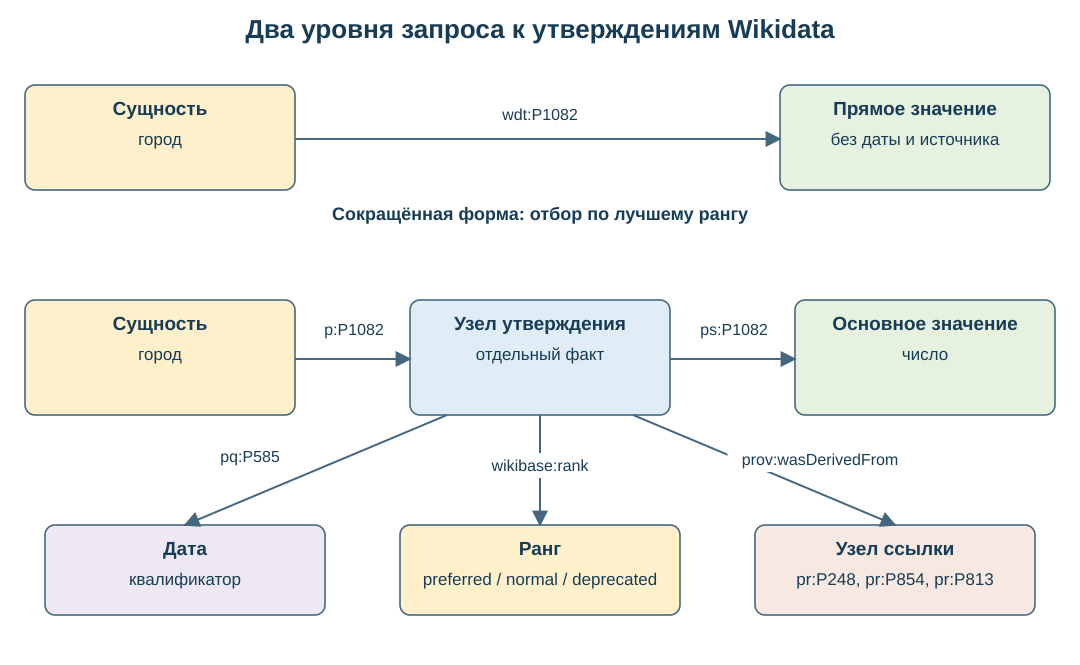

In [19]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="1080" height="665" viewBox="0 0 1080 665" style="max-width:100%;height:auto" role="img" aria-labelledby="full-title">
<title id="full-title">Два уровня запроса к утверждениям Wikidata</title><rect width="1080" height="665" fill="#ffffff"/>
<defs><marker id="full-arrow" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="8" markerHeight="8" orient="auto"><path d="M 0 0 L 10 5 L 0 10 z" fill="#45677e"/></marker></defs>
<g font-family="Arial, DejaVu Sans, sans-serif" fill="#173c55">
<text x="540" y="38" text-anchor="middle" font-size="26" font-weight="700">Два уровня запроса к утверждениям Wikidata</text><rect x="25" y="85" width="270" height="105" rx="10" fill="#fff0cc" stroke="#45677e" stroke-width="1.6"/><text x="160.0" y="115" text-anchor="middle" font-size="19" font-weight="700">Сущность</text><text x="160.0" y="145" text-anchor="middle" font-size="17">город</text><rect x="780" y="85" width="270" height="105" rx="10" fill="#e6f1e0" stroke="#45677e" stroke-width="1.6"/><text x="915.0" y="115" text-anchor="middle" font-size="19" font-weight="700">Прямое значение</text><text x="915.0" y="145" text-anchor="middle" font-size="17">без даты и источника</text><path d="M295 139 L780 139" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#full-arrow)"/><rect x="492.5" y="102" width="95" height="25" rx="3" fill="white"/><text x="540" y="120" text-anchor="middle" font-size="16">wdt:P1082</text><text x="540" y="220" text-anchor="middle" font-size="18" font-weight="700">Сокращённая форма: отбор по лучшему рангу</text><rect x="25" y="300" width="270" height="115" rx="10" fill="#fff0cc" stroke="#45677e" stroke-width="1.6"/><text x="160.0" y="330" text-anchor="middle" font-size="19" font-weight="700">Сущность</text><text x="160.0" y="360" text-anchor="middle" font-size="17">город</text><rect x="410" y="300" width="260" height="115" rx="10" fill="#e0edf7" stroke="#45677e" stroke-width="1.6"/><text x="540.0" y="330" text-anchor="middle" font-size="19" font-weight="700">Узел утверждения</text><text x="540.0" y="360" text-anchor="middle" font-size="17">отдельный факт</text><rect x="795" y="300" width="260" height="115" rx="10" fill="#e6f1e0" stroke="#45677e" stroke-width="1.6"/><text x="925.0" y="330" text-anchor="middle" font-size="19" font-weight="700">Основное значение</text><text x="925.0" y="360" text-anchor="middle" font-size="17">число</text><path d="M295 359 L410 359" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#full-arrow)"/><rect x="315.5" y="317" width="77" height="25" rx="3" fill="white"/><text x="354" y="335" text-anchor="middle" font-size="16">p:P1082</text><path d="M670 359 L795 359" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#full-arrow)"/><rect x="691.0" y="317" width="86" height="25" rx="3" fill="white"/><text x="734" y="335" text-anchor="middle" font-size="16">ps:P1082</text><rect x="45" y="525" width="280" height="90" rx="10" fill="#eee8f5" stroke="#45677e" stroke-width="1.6"/><text x="185.0" y="555" text-anchor="middle" font-size="19" font-weight="700">Дата</text><text x="185.0" y="585" text-anchor="middle" font-size="17">квалификатор</text><rect x="400" y="525" width="280" height="90" rx="10" fill="#fff0cc" stroke="#45677e" stroke-width="1.6"/><text x="540.0" y="555" text-anchor="middle" font-size="19" font-weight="700">Ранг</text><text x="540.0" y="585" text-anchor="middle" font-size="17">preferred / normal / deprecated</text><rect x="755" y="525" width="280" height="90" rx="10" fill="#f7e9e2" stroke="#45677e" stroke-width="1.6"/><text x="895.0" y="555" text-anchor="middle" font-size="19" font-weight="700">Узел ссылки</text><text x="895.0" y="585" text-anchor="middle" font-size="17">pr:P248, pr:P854, pr:P813</text><path d="M447 415 L185 525" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#full-arrow)"/><rect x="211.5" y="444" width="77" height="25" rx="3" fill="white"/><text x="250" y="462" text-anchor="middle" font-size="16">pq:P585</text><path d="M540 415 L540 525" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#full-arrow)"/><rect x="474.5" y="453" width="131" height="25" rx="3" fill="white"/><text x="540" y="471" text-anchor="middle" font-size="16">wikibase:rank</text><path d="M633 415 L895 525" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#full-arrow)"/><rect x="727.5" y="447" width="185" height="25" rx="3" fill="white"/><text x="820" y="465" text-anchor="middle" font-size="16">prov:wasDerivedFrom</text></g></svg>
"""

display(SVG(svg))

## Алгоритм разработки запроса

Когда известно, как работают шаблоны и операторы, разработку можно организовать по алгоритму лекции, который позволяет заметить ошибку до того, как запрос станет сложным.

| Действие | Что требуется зафиксировать |
|---|---|
| Сформулировать вопрос | Одна строка результата и её обязательные столбцы |
| Найти идентификаторы | QID класса, фиксированных сущностей и используемые PID |
| Построить минимальный шаблон | Два-три условия и небольшое ограничение выдачи |
| Проверить несколько решений | Соответствие исходным элементам и смыслу вопроса |
| Добавить подписи | Приоритет языков без потери сущностей |
| Добавлять по одному оператору | OPTIONAL, FILTER, путь, агрегат или полное утверждение |
| Разобрать повторения | Отличаются ли скрытые значения, типы или источники |
| Проверить пропуски | Какие обязательные свойства исключают сущности |
| Сузить и упростить | Убрать ненужные переменные и неселективные условия |
| Сохранить проверяемый результат | Запрос, входные данные, ответ, время и ограничения |


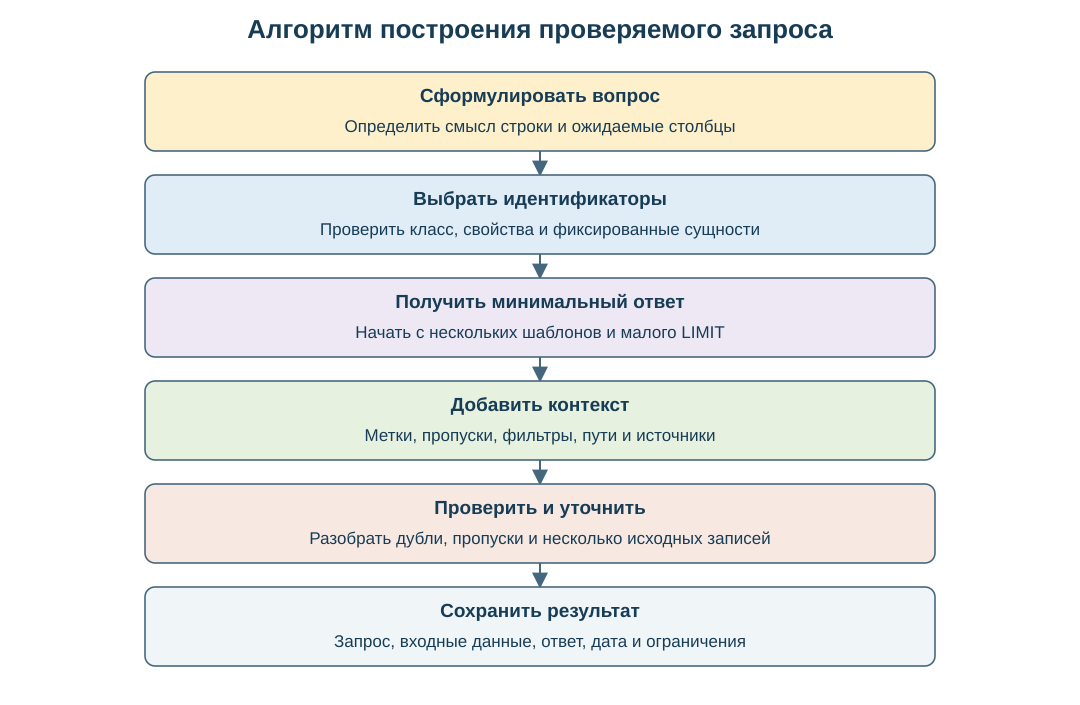

In [20]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="1080" height="705" viewBox="0 0 1080 705" style="max-width:100%;height:auto" role="img" aria-labelledby="algo-title">
<title id="algo-title">Алгоритм построения проверяемого запроса</title><rect width="1080" height="705" fill="#ffffff"/>
<defs><marker id="algo-arrow" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="8" markerHeight="8" orient="auto"><path d="M 0 0 L 10 5 L 0 10 z" fill="#45677e"/></marker></defs>
<g font-family="Arial, DejaVu Sans, sans-serif" fill="#173c55">
<text x="540" y="38" text-anchor="middle" font-size="26" font-weight="700">Алгоритм построения проверяемого запроса</text><rect x="145" y="72" width="790" height="79" rx="10" fill="#fff0cc" stroke="#45677e" stroke-width="1.6"/><text x="540.0" y="102" text-anchor="middle" font-size="19" font-weight="700">Сформулировать вопрос</text><text x="540.0" y="132" text-anchor="middle" font-size="17">Определить смысл строки и ожидаемые столбцы</text><path d="M540 151 L540 175" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#algo-arrow)"/><rect x="145" y="175" width="790" height="79" rx="10" fill="#e0edf7" stroke="#45677e" stroke-width="1.6"/><text x="540.0" y="205" text-anchor="middle" font-size="19" font-weight="700">Выбрать идентификаторы</text><text x="540.0" y="235" text-anchor="middle" font-size="17">Проверить класс, свойства и фиксированные сущности</text><path d="M540 254 L540 278" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#algo-arrow)"/><rect x="145" y="278" width="790" height="79" rx="10" fill="#eee8f5" stroke="#45677e" stroke-width="1.6"/><text x="540.0" y="308" text-anchor="middle" font-size="19" font-weight="700">Получить минимальный ответ</text><text x="540.0" y="338" text-anchor="middle" font-size="17">Начать с нескольких шаблонов и малого LIMIT</text><path d="M540 357 L540 381" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#algo-arrow)"/><rect x="145" y="381" width="790" height="79" rx="10" fill="#e6f1e0" stroke="#45677e" stroke-width="1.6"/><text x="540.0" y="411" text-anchor="middle" font-size="19" font-weight="700">Добавить контекст</text><text x="540.0" y="441" text-anchor="middle" font-size="17">Метки, пропуски, фильтры, пути и источники</text><path d="M540 460 L540 484" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#algo-arrow)"/><rect x="145" y="484" width="790" height="79" rx="10" fill="#f7e9e2" stroke="#45677e" stroke-width="1.6"/><text x="540.0" y="514" text-anchor="middle" font-size="19" font-weight="700">Проверить и уточнить</text><text x="540.0" y="544" text-anchor="middle" font-size="17">Разобрать дубли, пропуски и несколько исходных записей</text><path d="M540 563 L540 587" fill="none" stroke="#45677e" stroke-width="2" marker-end="url(#algo-arrow)"/><rect x="145" y="587" width="790" height="79" rx="10" fill="#f0f5f8" stroke="#45677e" stroke-width="1.6"/><text x="540.0" y="617" text-anchor="middle" font-size="19" font-weight="700">Сохранить результат</text><text x="540.0" y="647" text-anchor="middle" font-size="17">Запрос, входные данные, ответ, дата и ограничения</text></g></svg>
"""

display(SVG(svg))

## Индивидуальная работа по номеру студента

Номер $N$ в списке группы определяет предметную область и проверку, которую нужно особенно подробно объяснить. 

**Общее условие:** выберите набор сущностей своей области, ограничьте его конкретным городом, страной, автором, разработчиком или списком проверенных QID и подготовьте последовательность запросов, которая повторяет методику демонстрации. Для полного утверждения можно использовать факт одной из найденных сущностей или явно связанного с ними города, если у основного класса нет подходящего временного квалификатора.

| Файл запроса | Что требуется сделать и объяснить |
|---|---|
| `selection.rq` | Сформулировать вопрос и получить минимальную выборку; пояснить смысл строки |
| `optional_filter.rq` | Добавить необязательное поле и осмысленный фильтр; сравнить пропуски |
| `values_union.rq` | Ограничить отбор через `VALUES` или эквивалентную альтернативу `UNION` |
| `class_path.rq` | Сравнить прямой тип с путём классов; считать также уникальные сущности |
| `aggregate.rq` | Выполнить группировку и обосновать, что именно подсчитывается |
| `full_statement.rq` | Получить значение, квалификатор, ранг и источники; сохранить IRI утверждения |
| `ask.rq` | Проверить наличие факта и объяснить смысл `true` или `false` |
| `construct.rq` | Построить собственный граф, сохранить `.ttl` и прочитать его снова |
| `dbpedia.rq` | Выполнить смысловой запрос к DBpedia и сопоставить несколько сущностей |
| `focus_check.rq` | Подготовить дополнительную проверку, указанную в личном варианте |

Каждый запрос оформляется в четырёх частях: **вопрос → графовый шаблон → сопоставление → результат**; сохраняются текст `.rq`, фактический ответ, время получения, источник и ссылка в веб-редактор, скриншот. Все сетевые запросы выполняются через тот же `run_query` и RDFLib, что и в демонстрации. 


In [21]:
N_STUDENTS = 80
DOMAINS = [
    {"name": "люди", "question": "Люди, связанные с выбранным городом через место рождения.",
     "class_hint": "Q5; для более узкой темы добавьте профессию или иной содержательный признак.",
     "properties": "P31, P19, P569, P106; для контекста найдите датированное утверждение человека или города.",
     "context": "Например, временная связь с организацией либо P1082 связанного города."},
    {"name": "университеты", "question": "Университеты выбранной страны или города с учётом подклассов.",
     "class_hint": "Q3918; проверить прямые типы найденных организаций.",
     "properties": "P31, P279, P17 или P131, P856, P571.",
     "context": "Датированное утверждение университета либо P1082 выбранного города."},
    {"name": "города", "question": "Города выбранной страны и датированные значения населения.",
     "class_hint": "Найти целевой класс города, проверить его описание и иерархию.",
     "properties": "P31, P17, P1082, P585, P625, P856.",
     "context": "P1082 с P585, рангом и источником у одного из найденных городов."},
    {"name": "организации", "question": "Организации одного проверенного подкласса на выбранной территории.",
     "class_hint": "Найти конкретный класс организаций; не брать все организации мира.",
     "properties": "P31, P279, P17 или проверенная территориальная связь, P571, P856.",
     "context": "Датированное утверждение организации либо связанного города."},
    {"name": "произведения", "question": "Произведения выбранного автора одного содержательно заданного класса.",
     "class_hint": "Найти класс произведений и проверить свойство авторства для него.",
     "properties": "P31, свойство автора, дата публикации, язык или жанр; PID проверить на странице свойства.",
     "context": "Утверждение с датой или иным квалификатором; при отсутствии использовать явно связанный объект."},
    {"name": "технологии", "question": "Технологии или программные продукты выбранного класса и разработчика.",
     "class_hint": "Найти конкретный класс и проверить, что он обозначает продукт или технологию, а не организацию.",
     "properties": "P31, разработчик, дата выпуска, лицензия, P856; конкретные PID проверить.",
     "context": "Версия, выпуск или другое утверждение с квалификатором; при отсутствии использовать связанный объект."},
]
FOCUSES = [
    ("Пропуски", "Сравните обязательное и необязательное дополнительное свойство, объяснив потерю сущностей."),
    ("Языки меток", "Сравните приоритеты ru,en и en,ru и сохранение сущностей без подходящей метки."),
    ("Прямой тип и подклассы", "Покажите найденные только благодаря пути сущности и их прямые классы."),
    ("Многозначность", "Добавьте многозначное свойство и объясните число строк через скрытые различия."),
    ("Ранги", "Сравните лучшие утверждения со всеми неотвергнутыми и объясните разницу."),
    ("Место фильтра", "Сравните FILTER внутри OPTIONAL и снаружи, явно указав судьбу пропусков."),
    ("Две формы альтернативы", "Сравните VALUES и UNION по составу уникальных сущностей и числу строк."),
    ("Единица подсчёта", "Сравните COUNT(*) и COUNT(DISTINCT ?item), объяснив источник расхождения."),
    ("Временной диапазон", "Задайте точные включённую и исключённую границы диапазона и проверьте тип и точность даты."),
    ("Несколько источников", "Выведите IRI утверждения и ссылок, объяснив повторение факта в нескольких строках."),
    ("Логический ответ", "Объясните фактический ответ ASK; при false отличите отсутствие решения от доказанного отсутствия факта."),
    ("Новый RDF-граф", "Укажите, какие сведения исходной модели сохраняются и теряются при CONSTRUCT."),
    ("Сопоставление источников", "Сравните не только размеры выдач, но и минимум две проверенные связи сущностей."),
    ("Отсутствующее свойство", "Сопоставьте OPTIONAL и FILTER NOT EXISTS и точно сформулируйте вывод о пропуске."),
]


def student_variant(number):
    if isinstance(number, bool) or not isinstance(number, int) or not 1 <= number <= N_STUDENTS:
        raise ValueError("Номер студента должен быть целым числом от 1 до 80.")
    domain = DOMAINS[(number - 1) % len(DOMAINS)]
    focus = FOCUSES[(number - 1) // len(DOMAINS)]
    return {"number": number, **domain, "focus": focus[0], "focus_task": focus[1]}


variants = [student_variant(n) for n in range(1, N_STUDENTS + 1)]
show_table(["Номер", "Предметная область", "Индивидуальная проверка"], [
    [v["number"], v["name"], v["focus"]] for v in variants
])

Номер,Предметная область,Индивидуальная проверка
1,люди,Пропуски
2,университеты,Пропуски
3,города,Пропуски
4,организации,Пропуски
5,произведения,Пропуски
6,технологии,Пропуски
7,люди,Языки меток
8,университеты,Языки меток
9,города,Языки меток
10,организации,Языки меток


### Получение своего условия

Укажите номер в списке группы, после чего прочитайте автоматически выбранную предметную область и аналитическую проверку. Вариант задаётся номером, но конкретные QID и PID нужно проверить самостоятельно, повторяя показанную работу с Москвой.

In [22]:
STUDENT_NUMBER = 1  # замените своим номером в списке группы
variant = student_variant(STUDENT_NUMBER)
STUDENT_DIR = WORK_DIR / "student" / f"variant_{STUDENT_NUMBER:02d}"
STUDENT_DIR.mkdir(parents=True, exist_ok=True)
show_table(["Часть условия", "Ваш вариант"], [
    ["Номер", variant["number"]], ["Предметная область", variant["name"]],
    ["Вопрос", variant["question"]], ["Класс", variant["class_hint"]],
    ["Свойства", variant["properties"]], ["Контекстное утверждение", variant["context"]],
    ["Индивидуальная проверка", variant["focus"]], ["Что объяснить", variant["focus_task"]],
])
(STUDENT_DIR / "variant.json").write_text(json.dumps(variant, ensure_ascii=False, indent=2), encoding="utf-8")

Часть условия,Ваш вариант
Номер,1
Предметная область,люди
Вопрос,"Люди, связанные с выбранным городом через место рождения."
Класс,Q5; для более узкой темы добавьте профессию или иной содержательный признак.
Свойства,"P31, P19, P569, P106; для контекста найдите датированное утверждение человека или города."
Контекстное утверждение,"Например, временная связь с организацией либо P1082 связанного города."
Индивидуальная проверка,Пропуски
Что объяснить,"Сравните обязательное и необязательное дополнительное свойство, объяснив потерю сущностей."


535

### Первый запрос собственного варианта

**Вопрос.** Запишите свой вопрос в `STUDENT_QUESTION`, указав, что будет означать одна строка результата.

**Графовый шаблон.** Начальный шаблон имеет форму `?item → P31 → выбранный класс` и `?item → выбранное свойство → выбранная сущность`, а для более сложных связей его нужно отредактировать в соответствии с вопросом.

**Сопоставление.** Заполните проверенные идентификаторы, затем выполните ячейку, которая создаст самодостаточный запрос и отправит его через RDFLib; незаполненные поля не заменяются произвольными QID.

**Результат.** Таблица появится под ячейкой, рядом будут ссылка в WDQS и файл ответа, а существующий файл собственного запроса не перезаписывается автоматически.

In [23]:
def checked_qid(value):
    if not isinstance(value, str) or not re.fullmatch(r"Q[1-9][0-9]*", value):
        raise ValueError("Нужен проверенный QID вида Q649.")
    return value


def checked_pid(value):
    if not isinstance(value, str) or not re.fullmatch(r"P[1-9][0-9]*", value):
        raise ValueError("Нужен проверенный PID вида P19.")
    return value


STUDENT_CLASS_QID = ""
STUDENT_SCOPE_PID = ""
STUDENT_SCOPE_QID = ""
STUDENT_QUESTION = ""

if all([STUDENT_CLASS_QID, STUDENT_SCOPE_PID, STUDENT_SCOPE_QID, STUDENT_QUESTION.strip()]):
    class_id = checked_qid(STUDENT_CLASS_QID)
    property_id = checked_pid(STUDENT_SCOPE_PID)
    scope_id = checked_qid(STUDENT_SCOPE_QID)
    initial_query = full_query(f"""
SELECT DISTINCT ?item WHERE {{
  ?item wdt:P31 wd:{class_id} ; wdt:{property_id} wd:{scope_id} .
}}
ORDER BY ?item
LIMIT 20
""")
    path = STUDENT_DIR / "selection.rq"
    if not path.exists():
        path.write_text(initial_query, encoding="utf-8")
    else:
        print("Используется существующий запрос без перезаписи:", path)
    print("Ваш вопрос:", STUDENT_QUESTION)
    result = run_query(f"student_{STUDENT_NUMBER:02d}_selection", path.read_text(encoding="utf-8"))
else:
    print("Для своего запроса заполните вопрос и три проверенных идентификатора.")

Для своего запроса заполните вопрос и три проверенных идентификатора.


### Проверка и выполнение остальных файлов варианта

Перед запуском каждого собственного файла в отчёте должны быть сформулированы вопрос, шаблон, ожидаемый способ сопоставления и смысл результата, причём для DBpedia следует явно выбрать её endpoint. Синтаксическая проверка выявляет ошибки записи, но не проверяет правильность выбранного свойства или полноту ответа.

Следующая ячейка проверяет набор файлов, после чего при заполненном `STUDENT_QUERY_FILE` выполняет **один** выбранный запрос через RDFLib и показывает его ответ; это позволяет добавлять условия постепенно, как в демонстрации, не отправляя десятки запросов одновременно.

In [24]:
REQUIRED_QUERY_FILES = ["selection", "optional_filter", "values_union", "class_path", "aggregate",
                        "full_statement", "ask", "construct", "dbpedia", "focus_check"]
validation_rows = []
for name in REQUIRED_QUERY_FILES:
    path = STUDENT_DIR / f"{name}.rq"
    if not path.is_file():
        status = "файл ещё не создан"
    else:
        try:
            translateQuery(parseQuery(path.read_text(encoding="utf-8")))
            status = "синтаксис и префиксы разобраны; смысл проверяется отдельно"
        except Exception as exc:
            status = "ошибка: " + str(exc)
    validation_rows.append([path.name, status])
show_table(["Файл", "Состояние"], validation_rows)

STUDENT_QUERY_FILE = ""     # например: "optional_filter.rq"
STUDENT_TARGET = "WDQS"     # для файла dbpedia.rq укажите DBpedia

if STUDENT_QUERY_FILE:
    if Path(STUDENT_QUERY_FILE).name != STUDENT_QUERY_FILE or not STUDENT_QUERY_FILE.endswith(".rq"):
        raise ValueError("Укажите только имя .rq-файла внутри папки варианта.")
    source = STUDENT_DIR / STUDENT_QUERY_FILE
    if not source.is_file():
        print("Сначала создайте файл:", source)
    else:
        result = run_query(f"student_{STUDENT_NUMBER:02d}_{source.stem}",
                           source.read_text(encoding="utf-8"), target=STUDENT_TARGET)
        print("Ответы собственного варианта находятся в общей папке results с номером в имени.")
else:
    print("Выберите один подготовленный файл для следующего выполнения.")

Файл,Состояние
selection.rq,файл ещё не создан
optional_filter.rq,файл ещё не создан
values_union.rq,файл ещё не создан
class_path.rq,файл ещё не создан
aggregate.rq,файл ещё не создан
full_statement.rq,файл ещё не создан
ask.rq,файл ещё не создан
construct.rq,файл ещё не создан
dbpedia.rq,файл ещё не создан
focus_check.rq,файл ещё не создан


Выберите один подготовленный файл для следующего выполнения.
